# 📘 Notebook 04: Batch Size, How Many Examples per Step

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** About **six minutes** on an ordinary processor. Timings depend strongly on hardware: on a GPU, large batches are much faster per image than here, which changes the practical trade-off. Accuracies are for this small model and dataset.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain **batch**, **mini-batch** and **stochastic** gradient descent
- See why small batches give **noisy** gradients and large batches **smooth** ones
- Compare batch sizes fairly: per **epoch**, per **update**, and per **second**
- Apply the **linear scaling rule**: a larger batch usually needs a larger learning rate
- Choose a batch size for a given problem and machine

> **Prerequisites:** [Notebook 03: The Learning Rate](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/03_learning_rate.ipynb).
>
> 🔭 **Why this notebook matters:** the batch size decides how much memory a training run needs, how fast it goes on a GPU, and, together with the learning rate, how well the model learns. Choosing it wrongly can waste hours of computing or quietly cost accuracy.

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


## 1. How noisy is a gradient?

### Intuition first
The true gradient is the average over **all** 10,000 training images. Computing it at every step is expensive, so we estimate it from a **batch** of examples. A batch of 8 gives a quick, rough estimate; a batch of 2,048 an accurate but costly one. We measure how far each estimate is from the true gradient, at the start of training.

In [2]:
torch.manual_seed(0)
model = make_mlp(hidden=(128,))
def gradient(idx):
    model.zero_grad()
    F.cross_entropy(model(X_train[idx]), y_train[idx]).backward()
    return torch.cat([p.grad.flatten() for p in model.parameters()]).clone()

full = gradient(torch.arange(len(X_train)))
rows = {}
for batch in [8, 32, 128, 512, 2048]:
    sims = [F.cosine_similarity(gradient(torch.randint(0, len(X_train), (batch,))), full, dim=0).item() for _ in range(30)]
    rows[batch] = {"mean cosine similarity to the full gradient": np.mean(sims), "spread (std)": np.std(sims)}
pd.DataFrame(rows).T.rename_axis("batch size").round(3)

,mean cosine similarity to the full gradient,spread (std)
batch size,,
8,0.421,0.051
32,0.684,0.045
128,0.873,0.036
512,0.966,0.008
2048,0.991,0.002


**What we see.** The cosine similarity measures how well a batch gradient points in the same direction as the true one (1 means the same direction). A batch of **8** gives **0.42**: a rough guess that points only partly the right way. The estimate improves quickly with size: **0.68** at 32, **0.87** at 128, **0.97** at 512 and **0.99** at 2,048. Beyond a few hundred images, a larger batch adds almost no accuracy to the direction, only cost. Small batches are **noisy**, and that noise is not only a defect: it makes small-batch training wander, which can help it escape poor regions, as the next section shows.

## 2. The same epochs, different batch sizes

We train for 15 epochs with each batch size, keeping the learning rate fixed at Adam's default 0.001.

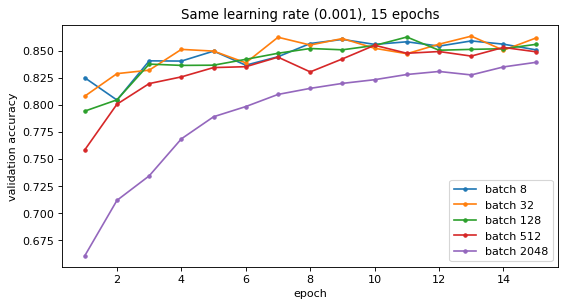

,updates,seconds,best val acc,final val acc
batch size,,,,
8,18750.0,163.953,0.860,0.851
32,4695.0,46.230,0.863,0.862
128,1185.0,16.961,0.863,0.856
512,300.0,7.522,0.855,0.849
2048,75.0,3.745,0.839,0.839


In [3]:
results, histories = {}, {}
for batch in [8, 32, 128, 512, 2048]:
    h = fit(make_mlp(hidden=(128,)), epochs=15, batch=batch)
    histories[batch] = h
    results[batch] = {"updates": 15 * ((10000 + batch - 1) // batch), "seconds": h.attrs["seconds"],
                      "best val acc": h["val acc"].max(), "final val acc": h["val acc"].iloc[-1]}
fig, ax = plt.subplots(figsize=(8, 4))
for batch, h in histories.items():
    ax.plot(h.index, h["val acc"], marker="o", ms=3, label=f"batch {batch}")
ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy"); ax.legend(); ax.set_title("Same learning rate (0.001), 15 epochs")
plt.show()
pd.DataFrame(results).T.rename_axis("batch size").round(3)

**What we see.** With the learning rate held fixed, the batch size changes **how many updates** the network gets in 15 epochs, from 18,750 (batch 8) to only 75 (batch 2,048):
- Batches of **8 to 128** all reach a best validation accuracy of about **86.0 to 86.3%**, a difference within the seed-to-seed spread of Notebook 01. Batch 8 is noisier from epoch to epoch and takes **164 seconds**, almost ten times longer than batch 128 (**17 s**): on a processor, tiny batches waste time on overhead.
- Batch **512** is a little behind (85.5%), and batch **2,048** clearly so (**83.9%**, still climbing at epoch 15): with so few updates it simply has not finished learning. In the chart its curve rises slowly from 66% after the first epoch.

So a large batch is not "worse" in itself; at a fixed learning rate and a fixed number of epochs it takes **fewer steps** and needs either more epochs or a larger learning rate.

## 3. A fair comparison: scale the learning rate too

### Intuition first
A batch 4 times larger averages 4 times as many examples, so its gradient is less noisy, but the model takes 4 times **fewer** steps per epoch. The **linear scaling rule** (Goyal et al., [*Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour*](https://arxiv.org/abs/1706.02677), 2017) compensates: multiply the learning rate by the same factor as the batch. It was found for SGD on very large batches; we test it here with Adam, as a rule of thumb.

In [4]:
scaled = {}
for batch in [32, 128, 512, 2048]:
    lr = 1e-3 * batch / 128
    h = fit(make_mlp(hidden=(128,)), epochs=15, batch=batch, lr=lr)
    scaled[batch] = {"learning rate": lr, "best val acc": h["val acc"].max(), "final val acc": h["val acc"].iloc[-1], "seconds": h.attrs["seconds"]}
pd.DataFrame(scaled).T.rename_axis("batch size").round(4)

,learning rate,best val acc,final val acc,seconds
batch size,,,,
32,2.000e-04,0.857,0.857,52.737
128,1.000e-03,0.863,0.856,15.232
512,4.000e-03,0.864,0.861,6.236
2048,1.600e-02,0.851,0.851,3.692


**What we see.** With the learning rate scaled in proportion to the batch, the large batches catch up: batch **512** with learning rate 0.004 reaches **86.4%**, as good as batch 128 (86.3%), in **6 seconds** instead of 15. Batch **2,048** with 0.016 reaches **85.1%**, up from 83.9%, in under 4 seconds, though still slightly behind. Batch **32** with a smaller rate (0.0002) is no better than before and the slowest. The rule of thumb works reasonably well up to a point; at very large batches the learning rate needed becomes so large that training turns unstable, which is why large-batch training in practice also uses a **warmup** (Notebook 10).

## ⚠️ Common pitfalls

- **Changing the batch size and nothing else.** Fewer updates per epoch need either more epochs or a larger learning rate.
- **Assuming bigger batches are always faster.** On a processor, per-image speed barely improves; on a GPU it does, up to the memory limit.
- **Using batch size 1 "for accuracy".** Single-example steps are extremely noisy and slow; they rarely help.
- **Forgetting batch normalisation.** With very small batches, the batch statistics it relies on become unreliable (Notebook 10).
- **Running out of memory and blaming the model.** Halve the batch size first.

## ✏️ Exercises

### Exercise 1 (Equal number of updates)
Give batch 2048 the same number of **updates** as batch 128 gets in 15 epochs (that is, 16 times as many epochs) with the default learning rate. Does it catch up? How long does it take?

In [5]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
updates_128 = 15 * 79
epochs_2048 = updates_128 // 5 + 1
h = fit(make_mlp(hidden=(128,)), epochs=epochs_2048, batch=2048)
print(f"batch 2048, {epochs_2048} epochs: best val acc {h['val acc'].max():.4f}, {h.attrs['seconds']:.0f} s")
```

*In our run batch 2,048 with 238 epochs reached 86.2%, the same as batch 128 in 15 epochs, but it processed 16 times more images and took about 79 seconds instead of 17. With enough updates the large batch catches up. The question is never only "which batch is better" but "better per what": per update, per image or per second.*
</details>

### Exercise 2 (Noise as regulariser)
Train the 1024-neuron network of Notebook 02 for 40 epochs with batch 32 and with batch 1024 (learning rate scaled with the batch). Compare the gap between training and validation accuracy.

In [6]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for batch in [32, 1024]:
    h = fit(make_mlp(hidden=(1024,)), epochs=40, batch=batch, lr=1e-3 * batch / 128)
    print(f"batch {batch}: train acc {h['train acc'].iloc[-1]:.4f}, val acc {h['val acc'].iloc[-1]:.4f}, gap {h['train acc'].iloc[-1] - h['val acc'].iloc[-1]:.4f}")
```

*Small batches add noise to every step, and this noise is often described as a mild regulariser. In our run the effect did not appear: the gap was 12.7 points with batch 32 and 12.2 with batch 1,024, a difference within noise. Whatever regularising effect small batches have is small here, much smaller than the choices studied in Notebook 09.*
</details>

## 🔑 Key takeaways

- The **batch size** sets how many examples estimate each gradient: small batches are **noisy and many**, large batches **accurate and few**.
- Compare batch sizes **per update, per image and per second**; with a fixed learning rate, large batches look worse simply because they take fewer steps.
- Scale the **learning rate** with the batch size as a starting point.
- In practice: the largest batch that fits comfortably in memory, with a tuned learning rate; 32 to 512 is a common range.

---
**Next:** *Notebook 05: Neurons and Layers*, how big and how deep the network should be.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*